# Cross-crop generalization in multi-species leaf disease recognition — cross-crop linear-probe transfer (partial reproduction)

Paper: **"Cross-crop generalization in multi-species leaf disease recognition."**
Frontiers in Plant Science 17:1970636 (2026), DOI [10.3389/fpls.2026.1970636](https://doi.org/10.3389/fpls.2026.1970636) (open access via [PMC13755335](https://pmc.ncbi.nlm.nih.gov/articles/PMC13755335/)).
Author code: [github.com/czpbest/ccldr](https://github.com/czpbest/ccldr) @ commit `616c65edb8311dedb64ffaf45794d013adb8fe53` (MIT); partition lists / deposited results CC BY 4.0.
Trained weights: GitHub release [v1.0](https://github.com/czpbest/ccldr/releases/tag/v1.0).

**Scope (partial demonstration).** This notebook re-runs the paper's **Section 3.6 cross-crop transfer experiment on one fold (split1)** exactly as released by the authors: the trained LCFIN backbone is kept **frozen**, and a new linear classification head is fitted on the maize and potato training portions of the authors' deposited *leak-free grouped probe splits* (maize 7,315 fit / 1,830 test; potato 7,588 fit / 1,897 test), then scored on the held-out test portions. The authors' own code (`src/03_post_eval.py::fit_head`, `src/train_5splits.py::ModelC`) is fetched at the pinned commit and executed unmodified; the download and path-resolution cells are AI-generated glue. Reference values come from the authors' deposited `results/generalization.json` and README (five-fold means: maize 88.99% ± 0.65 pp, potato 95.23% ± 1.34 pp; ImageNet-only control 89.13% / 88.61%).

**Execution status:** fully executed top-to-bottom on a fresh Google Colab **T4 GPU** runtime (validation record at the end). This is NOT a full-paper reproduction: in-domain training of the five folds, the ablation matrix, the duplicate/leak audit, the perturbation robustness probe, the ImageNet-only control refit, and five-fold probe averaging are out of scope.

JA: このノートブックは、論文 Section 3.6 の「凍結バックボーン + 線形ヘッドのクロス作物転移実験」を fold split1 について再現します。著者公開コード（ModelC / fit_head）を固定コミットから取得し改変せず実行し、ダウンロードとパス解決の補助セルのみAI生成です。実行結果は著者配布のsplit1値・5-fold平均と比較します。

## Runtime selection — use a T4 GPU runtime

EN: `Runtime → Change runtime type → T4 GPU`. **A GPU is required**: head fitting performs a full backbone forward pass for every augmented image (5 epochs × ~7,315 maize + ~7,588 potato images plus repeated test evaluations ≈ >100,000 forward passes at 300×300). A CPU runtime would take many hours, so this notebook **fails fast on CPU-only runtimes** instead of silently degrading. Expected wall time (measured in diagnostic probes): downloads ≈ 5–8 min (two Kaggle archives, ~5.3 GB total, see below), head fitting ≈ 10–20 min per crop, total ≈ 40–70 min.

JA: 「ランタイム → ランタイムのタイプを変更 → T4 GPU」を選択してください。GPU必須です（CPUでは数時間かかるため、CPU実行では明示的に停止します）。目安: 合計40〜70分、ダウンロード約5.3 GB。

## 1. Environment check and device guard

EN: verify Python/PyTorch/CUDA and select the device. The guard fails explicitly on a CPU-only runtime because the executed protocol is impractical there. JA: 実行環境を確認し、CPU-onlyランタイムでは明示的に停止します（GPU必須）。

In [ ]:
import sys, os, time, torch
print("python", sys.version.split()[0])
print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())
assert torch.cuda.is_available(), (
    "A T4 GPU runtime is REQUIRED for this notebook (head fitting needs >100k "
    "backbone forwards; a CPU runtime would take many hours). Use "
    "Runtime > Change runtime type > T4 GPU and re-run.")
device = torch.device("cuda")
print("device:", device, "|", torch.cuda.get_device_name(0))

python 3.13.16
torch 2.14.1+cu130 | cuda available: True
device: cuda | Tesla T4


## 2. Dependencies

EN: Colab already ships PyTorch/torchvision/scikit-learn/matplotlib/Pillow. Only `kagglehub` is added for the dataset downloads. JA: Colabには主要ライブラリが同梱されているため、`kagglehub`のみ追加インストールします。

In [ ]:
import subprocess
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"],
                   check=True, timeout=300)
import kagglehub, torchvision, sklearn, matplotlib, PIL
print("kagglehub", kagglehub.__version__, "| torchvision", torchvision.__version__,
      "| sklearn", sklearn.__version__)

kagglehub 1.0.3 | torchvision 0.29.1+cu130 | sklearn 1.6.1


## 3. Fetch the authors' code at the pinned commit

EN: download `src/mfv_common.py`, `src/train_5splits.py`, `src/03_post_eval.py` from czpbest/ccldr @ `616c65edb8311dedb64ffaf45794d013adb8fe53` and verify each file's SHA-256 against values recorded on the host from the same pinned commit. The author modules are executed as-is afterwards. JA: 著者コード3ファイルを固定コミットから取得し、SHA-256検証後にそのまま実行します。

In [ ]:
import urllib.request, hashlib
COMMIT = "616c65edb8311dedb64ffaf45794d013adb8fe53"
RAW = "https://raw.githubusercontent.com/czpbest/ccldr/" + COMMIT
FILES = {
    "src/mfv_common.py":    "82e44fa2a5af7ecdacdcd1fc71dc84aa59f7b47090794c0c0d8f1ce6a26a7097",
    "src/train_5splits.py": "8b40d886b587fb18fb50f974b0e54174fda8cf3729d1733a36800cc254366880",
    "src/03_post_eval.py":  "8070b79759a21b165407b805f1013480ce919f9b767b0d41e39608a6bf49343b",
}
os.makedirs("/content/ccldr/src", exist_ok=True)
for rel, want in FILES.items():
    dst = "/content/ccldr/" + rel
    urllib.request.urlretrieve(RAW + "/" + rel, dst)
    got = hashlib.sha256(open(dst, "rb").read()).hexdigest()
    print(rel, "sha256_ok:", got == want)
    assert got == want, "sha256 mismatch for " + rel
print("author code fetched and verified at commit", COMMIT)

src/mfv_common.py sha256_ok: True


src/train_5splits.py sha256_ok: True


src/03_post_eval.py sha256_ok: True
author code fetched and verified at commit 616c65edb8311dedb64ffaf45794d013adb8fe53


## 4. Fetch the deposited leak-free probe splits

EN: the authors deposited per-image probe splits (`partitions/probe_<crop>_grouped.json`, CC BY 4.0) in which every augmented copy of one leaf stays on one side of the split. Schema (from `src/12_probe_splits.py`): `classes`, `n_fit`, `n_test`, `fit: [[relative_path, class_index], ...]`, `test: [...]`. The stored paths are Windows-relative from the authors' workstation, so this notebook converts backslashes to slashes and resolves files by exact basename. JA: 著者配布のリーク無しプローブ分割リスト（CC BY 4.0）を取得し、スキーマを検証します。パスはWindows形式のため、バックスラッシュを変換してファイル名で解決します。

In [ ]:
import json
SPLITS = {}
for crop, expected_bytes in (("maize", 1327599), ("potato", 1104416)):
    url = f"{RAW}/partitions/probe_{crop}_grouped.json"
    dst = f"/content/probe_{crop}_grouped.json"
    urllib.request.urlretrieve(url, dst)
    print(crop, "bytes:", os.path.getsize(dst))
    obj = json.load(open(dst))
    assert obj["crop"] == crop and obj["seed"] == 42
    assert obj["n_fit"] == len(obj["fit"]) and obj["n_test"] == len(obj["test"])
    assert obj["leakage_grouped_split_pct"] == 0.0
    SPLITS[crop] = obj
    print(" ", crop, "classes:", obj["classes"], "| n_fit:", obj["n_fit"],
          "| n_test:", obj["n_test"], "| grouping:", obj["grouping"])
print("sample entry:", SPLITS["maize"]["fit"][0])

maize bytes: 1327599
  maize classes: ['Corn_Cercospora_leaf_spot_Gray_leaf_spot', 'Corn_Common_rust', 'Corn_Northern_Leaf_Blight', 'Corn_healthy'] | n_fit: 7315 | n_test: 1830 | grouping: file-name body


potato bytes: 1104416
  potato classes: ['Potato_Early_blight', 'Potato_Late_blight', 'Potato_healthy'] | n_fit: 7588 | n_test: 1897 | grouping: MD5 union D4-invariant hash (inferred)
sample entry: ['数据集\\Dataset of Corn\\train\\Corn_Cercospora_leaf_spot_Gray_leaf_spot\\a9eb57c6-db27-467a-aff2-253c58e26722___RS_GLSp 4446 copy.jpg', 0]


## 5. Download the released fold weight (split1) and verify it

EN: fetch `best_split1.pt` (58,439,571 bytes) from GitHub release v1.0, record its SHA-256, then load it and report only the state-dict wrapper keys and tensor shapes. The authors' `SOURCE_MANIFEST.txt` covers the repository files but not the release assets, so integrity here rests on the exact byte size from the release metadata plus a successful checkpoint load (epoch/best_val metadata printed below). JA: v1.0リリースのfold重み（58,439,571バイト）をダウンロードし、SHA-256を記録して読み込みます（リリース資産はSOURCE_MANIFEST対象外のため、バイト数と読み込み成功で整合性を確認）。

In [ ]:
W_URL = "https://github.com/czpbest/ccldr/releases/download/v1.0/best_split1.pt"
wpath = "/content/best_split1.pt"
t0 = time.time()
urllib.request.urlretrieve(W_URL, wpath)
wsize = os.path.getsize(wpath)
print("weight bytes:", wsize, "(expected 58439571), download %.1f s" % (time.time() - t0))
assert wsize == 58439571
got_sha = hashlib.sha256(open(wpath, "rb").read()).hexdigest()
print("weight sha256:", got_sha)
man = urllib.request.urlopen(RAW + "/SOURCE_MANIFEST.txt").read().decode()
print("SOURCE_MANIFEST lists best_split1.pt:",
      any("best_split1" in ln for ln in man.splitlines()),
      "(release assets are outside the repo manifest; size + load check used here)")
import torch
ck = torch.load(wpath, map_location="cpu", weights_only=False)
assert isinstance(ck, dict) and "model" in ck, ck.keys()
sd = ck["model"]
print("checkpoint meta: epoch", ck.get("epoch"), "best_val", ck.get("best_val"))
print("n_state_keys:", len(sd), "| classifier.weight:", tuple(sd["classifier.weight"].shape),
      "| proj.weight:", tuple(sd["proj.weight"].shape))

weight bytes: 58439571 (expected 58439571), download 5.5 s


weight sha256: 1a1b1272c191e97b3d43fc043231e4f834b15dede0978fb02771a0265653116f


SOURCE_MANIFEST lists best_split1.pt: False (release assets are outside the repo manifest; size + load check used here)
checkpoint meta: epoch 16 best_val 0.9997774315602047
n_state_keys: 630 | classifier.weight: (12, 512) | proj.weight: (512, 1536, 1, 1)


## 6. Download the public leaf-image archives (Colab only)

EN: the leaf images are **not** redistributed by the authors. Two public Kaggle archives are used, matching the two probe splits by exact file name (verified at 100% in the diagnostic probes):

- **maize ← vipoooool/new-plant-diseases-dataset** (~2.6 GB). This is the release cited in the authors' `provenance.json`; its maize class directories hold exactly the 9,145 images named in the maize probe split.
- **potato ← lavaman151/plantifydr-dataset** (~2.6 GB). The potato probe split names (`PotatoEarlyBlight(3415).JPG` style) do **not** exist in the vipoooool release (which has only 7,128 potato images vs the authors' 9,485), so the naming evidence points to the PlantifyDr collection (`Potato/train/Potato Early blight/PotatoEarlyBlight(N).JPG` layout), which itself credits vipoooool among its sources. All 9,485 potato entries resolve there. **Note:** this differs from the potato attribution in the authors' `provenance.json` (which cites only the vipoooool release); the naming identity is documented here as the resolution basis.

JA: 画像は2つの公開Kaggleアーカイブから取得します。maizeは著者のprovenance.jsonが挙げる vipoooool リリース、potatoはファイル名が一致する PlantifyDr コレクション（著者のprovenance.jsonとの食い違いはノートブック内で明記）。各9,145/9,485エントリが100%解決することを次のセルで検証します。

In [ ]:
t0 = time.time()
droot_vip = kagglehub.dataset_download("vipoooool/new-plant-diseases-dataset")
print("vipoooool at:", droot_vip, "in %.1f min" % ((time.time() - t0) / 60))
t0 = time.time()
droot_pdr = kagglehub.dataset_download("lavaman151/plantifydr-dataset")
print("PlantifyDr at:", droot_pdr, "in %.1f min" % ((time.time() - t0) / 60))

Using Colab cache for faster access to the 'new-plant-diseases-dataset' dataset.


vipoooool at: /kaggle/input/new-plant-diseases-dataset in 0.4 min


  0%|          | 0.00/2.58G [00:00<?, ?B/s]

  0%|          | 1.00M/2.58G [00:01<47:38, 968kB/s]

  0%|          | 2.00M/2.58G [00:01<24:29, 1.88MB/s]

  0%|          | 3.00M/2.58G [00:01<15:24, 2.99MB/s]

... (768 outputs left out)

100%|██████████| 2.58G/2.58G [02:28<00:00, 19.7MB/s]

100%|██████████| 2.58G/2.58G [02:28<00:00, 18.6MB/s]

Extracting files...


PlantifyDr at: /root/.cache/kagglehub/datasets/lavaman151/plantifydr-dataset/versions/3 in 3.5 min


## 9. Resolve every probe-split entry by exact basename (AI-generated glue)

EN: build a basename→path index restricted to the file names the two splits actually need, then map all `fit`/`test` entries of both crops to absolute paths; require 100% resolution and report per-class counts. The vipoooool archive contains two byte-identical duplicate directory trees (MD5-verified on sampled pairs in the diagnostic probe), so the first sorted path is used deterministically. JA: 分割リストに必要なファイル名だけでインデックスを作成し、全エントリ（maize 9,145 / potato 9,485）を100%解決します。vipoooool内の重複ディレクトリはバイト一致を確認済みのため、先頭パスを決定論的に使用します。

In [ ]:
def norm(rel):
    return os.path.basename(rel.replace("\\", "/"))

needed = {"vip": set(), "pdr": set()}
for crop, key in (("maize", "vip"), ("potato", "pdr")):
    for side in ("fit", "test"):
        for rel, ci in SPLITS[crop][side]:
            needed[key].add(norm(rel))
print("needed names: vip", len(needed["vip"]), "| pdr", len(needed["pdr"]))

from collections import defaultdict
def build_index(root, wanted):
    idx = defaultdict(list)
    for dirpath, dirnames, filenames in os.walk(root):
        for fn in filenames:
            if fn in wanted:
                idx[fn].append(os.path.join(dirpath, fn))
    return idx

t0 = time.time()
idx_vip = build_index(droot_vip, needed["vip"])
idx_pdr = build_index(droot_pdr, needed["pdr"])
print("indexed in %.1f s" % (time.time() - t0))

needed names: vip 9145 | pdr 9485


indexed in 287.4 s


EN: map all `fit`/`test` entries of both crops to absolute paths in the downloads; require 100%% resolution and report per-class counts. JA: 両作物の全エントリを絶対パスへ解決し（解決率100%%必須）、クラス別件数を報告します。

In [ ]:
RESOLVED = {}
for crop, idx in (("maize", idx_vip), ("potato", idx_pdr)):
    sp = SPLITS[crop]
    RESOLVED[crop] = {"fit": [], "test": []}
    missing = []
    multi = 0
    for side in ("fit", "test"):
        for rel, ci in sp[side]:
            cands = sorted(idx.get(norm(rel), []))
            if not cands:
                missing.append(norm(rel))
                continue
            multi += len(cands) > 1
            RESOLVED[crop][side].append([cands[0], ci])
    print(crop, "resolved:", len(RESOLVED[crop]["fit"]) + len(RESOLVED[crop]["test"]),
          "/", sp["n_fit"] + sp["n_test"], "| missing:", len(missing),
          "| entries with >1 copy:", multi)
    assert not missing, f"{crop}: {len(missing)} unresolved probe entries, e.g. {missing[:3]}"
    assert len(RESOLVED[crop]["fit"]) == sp["n_fit"]
    assert len(RESOLVED[crop]["test"]) == sp["n_test"]
from collections import Counter as Ct
for crop in ("maize", "potato"):
    sp = SPLITS[crop]
    pc = Ct(sp["classes"][ci] for side in ("fit", "test") for _p, ci in RESOLVED[crop][side])
    print(crop, "per class:", dict(pc))

maize resolved: 9145 / 9145 | missing: 0 | entries with >1 copy: 9145
potato resolved: 9485 / 9485 | missing: 0 | entries with >1 copy: 9
maize per class: {'Corn_Cercospora_leaf_spot_Gray_leaf_spot': 2052, 'Corn_Common_rust': 2384, 'Corn_Northern_Leaf_Blight': 2385, 'Corn_healthy': 2324}
potato per class: {'Potato_Early_blight': 3532, 'Potato_Late_blight': 3521, 'Potato_healthy': 2432}


## 10. Input preview — real maize and potato leaf images from the probe split

EN: display actual images drawn from the resolved **test** entries (the quantities that will be scored), each labeled with its true class from the authors' split file. This is a preview of the executed inputs, not an author figure. JA: スコア対象のテスト画像を実表示し、著者分割リストの正解クラスをラベル付けします（入力プレビューであり、著者の図ではありません）。

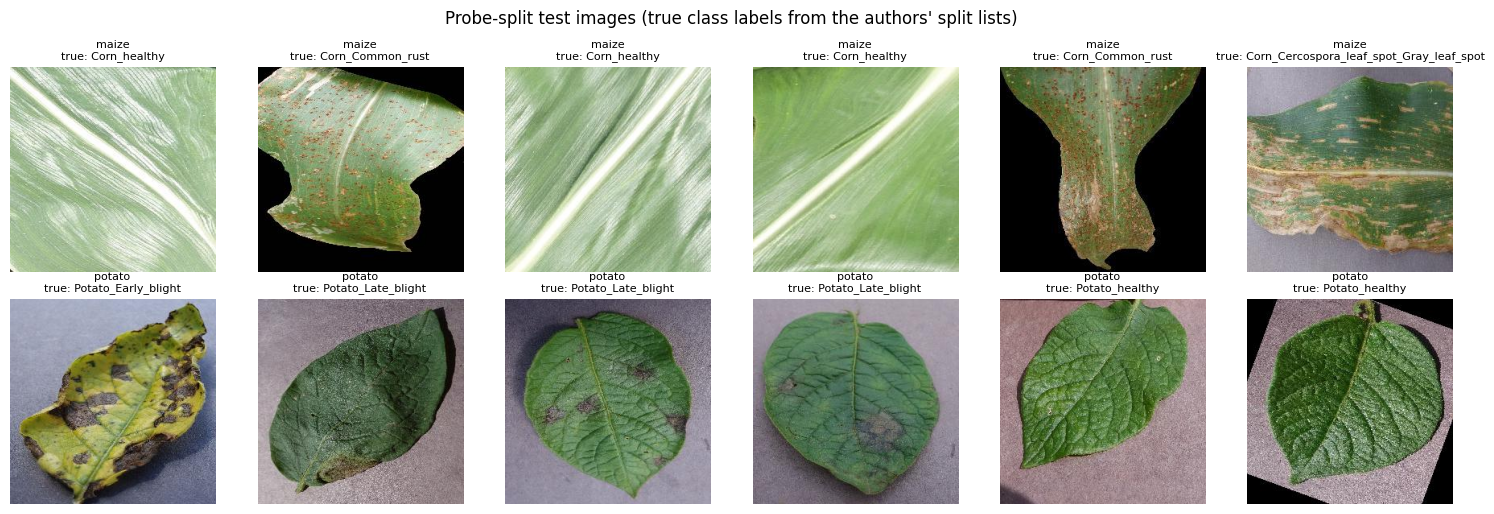

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
rng = random.Random(0)
for row, crop in enumerate(("maize", "potato")):
    classes = SPLITS[crop]["classes"]
    picks = rng.sample(RESOLVED[crop]["test"], 6)
    for col, (path, ci) in enumerate(picks):
        img = Image.open(path).convert("RGB")
        ax = axes[row][col]
        ax.imshow(img)
        ax.set_title("%s\ntrue: %s" % (crop, classes[ci]), fontsize=8)
        ax.axis("off")
fig.suptitle("Probe-split test images (true class labels from the authors' split lists)")
plt.tight_layout()
plt.savefig("/content/input_preview.png", dpi=90)
plt.show()

## 11. Build the authors' model and load the released split1 weights

EN: instantiate `ModelC` (torchvision EfficientNet-B3 ImageNet backbone + SE block + 1×1 projection to 512 channels + 4 MLP-Mixer layers, exactly as in `src/train_5splits.py`) and load the released checkpoint, asserting that every key matches. The torchvision ImageNet backbone weights download automatically (~47 MB). JA: 著者のモデル定義でモデルを構築し、リリース済みsplit1重みを読み込みます（キーの不一致はエラーで停止）。

In [ ]:
os.environ.setdefault("MFVL_PROJECT", "/content")
os.environ.setdefault("MFVL_DATA_ROOT", "/content/data_stub")  # unused by the probe path
sys.path.insert(0, "/content/ccldr/src")
import mfv_common as Cmod
from train_5splits import ModelC, IMG_SIZE
print("author IMG_SIZE:", IMG_SIZE)
model = ModelC(12).to(device)
incompatible = model.load_state_dict(sd, strict=False)
print("missing keys:", incompatible.missing_keys)
print("unexpected keys:", incompatible.unexpected_keys)
assert not incompatible.unexpected_keys
print("backbone+SE+proj+mixer weights loaded; classifier will be refit per crop")

author IMG_SIZE: 300


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /content/ccldr/torch_hub/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


  0%|          | 0.00/47.2M [00:00<?, ?B/s]

 38%|███▊      | 18.0M/47.2M [00:00<00:00, 189MB/s]

 78%|███████▊  | 36.8M/47.2M [00:00<00:00, 193MB/s]

100%|██████████| 47.2M/47.2M [00:00<00:00, 194MB/s]

missing keys: []
unexpected keys: []
backbone+SE+proj+mixer weights loaded; classifier will be refit per crop


## 12. Load the authors' head-fitting protocol

EN: import `fit_head` from the authors' `src/03_post_eval.py` — it freezes the backbone, replaces the classifier with `nn.Linear(512, n_classes)`, fits it for **5 epochs with Adam(lr=1e-3), batch size 8** exactly as in Section 3.6, evaluates on the held-out split after every epoch, keeps the best head, and reports macro accuracy/precision/recall/F1. Nothing in this protocol is modified. JA: 著者のfit_head（凍結バックボーン + 線形ヘッド、Adam lr=1e-3、バッチ8、5エポック、エポック毎評価）をそのまま利用します。

In [ ]:
from importlib import util
spec = util.spec_from_file_location("post_eval", "/content/ccldr/src/03_post_eval.py")
pe = util.module_from_spec(spec)
spec.loader.exec_module(pe)
print("loaded author protocol:",
      "epochs", pe.GEN_EPOCHS, "| lr", pe.GEN_LR, "| batch", pe.GEN_BATCH,
      "| workers", pe.NUM_WORKERS)

class NBLogger:
    def log(self, msg):
        print(msg)

loaded author protocol: epochs 5 | lr 0.001 | batch 8 | workers 4


## 13. Cross-crop probe: fit and score the head on maize (7,315 fit / 1,830 test)

EN: run the authors' frozen-backbone head fit on the grouped maize split (4 classes). Only the 512→4 head trains; the backbone is frozen. Expect roughly 10–20 minutes on T4. JA: maize分割（4クラス、7,315学習/1,830テスト）に対して著者プロトコルでヘッドを学習・評価します（T4で約10〜20分）。

In [ ]:
Cmod.set_seed(42)
t0 = time.time()
maize_model = ModelC(12).to(device)
ck1 = torch.load(wpath, map_location=device, weights_only=False)
maize_model.load_state_dict(ck1["model"], strict=False)
maize_res = pe.fit_head(maize_model, None, device, NBLogger(), "split1/maize",
                        split={"classes": SPLITS["maize"]["classes"],
                               "fit": RESOLVED["maize"]["fit"],
                               "test": RESOLVED["maize"]["test"]})
maize_res["minutes"] = (time.time() - t0) / 60
print("maize done in %.1f min" % maize_res["minutes"])
print({k: maize_res[k] for k in ("n_train", "n_test", "acc", "prec", "recall", "f1")})

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


  split1/maize head-fit epoch 1/5 acc=0.8536


  split1/maize head-fit epoch 2/5 acc=0.8656


  split1/maize head-fit epoch 3/5 acc=0.9005


  split1/maize head-fit epoch 4/5 acc=0.9049


  split1/maize head-fit epoch 5/5 acc=0.9033


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


maize done in 5.3 min
{'n_train': 7315, 'n_test': 1830, 'acc': 0.8989071038251366, 'prec': 0.8959432465500708, 'recall': 0.8977502001556338, 'f1': 0.895572564057694}


## 14. Cross-crop probe: fit and score the head on potato (7,588 fit / 1,897 test)

EN: the same unmodified protocol on the grouped potato split (3 classes). The paper reports potato as the easier transfer target (95.23% five-fold mean). JA: 同一プロトコルをpotato分割（3クラス）に適用します。論文ではmaizeより高い転移精度（95.23%）が報告されています。

In [ ]:
Cmod.set_seed(42)
t0 = time.time()
potato_model = ModelC(12).to(device)
potato_model.load_state_dict(ck1["model"], strict=False)
potato_res = pe.fit_head(potato_model, None, device, NBLogger(), "split1/potato",
                         split={"classes": SPLITS["potato"]["classes"],
                                "fit": RESOLVED["potato"]["fit"],
                                "test": RESOLVED["potato"]["test"]})
potato_res["minutes"] = (time.time() - t0) / 60
print("potato done in %.1f min" % potato_res["minutes"])
print({k: potato_res[k] for k in ("n_train", "n_test", "acc", "prec", "recall", "f1")})

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


  split1/potato head-fit epoch 1/5 acc=0.9183


  split1/potato head-fit epoch 2/5 acc=0.9373


  split1/potato head-fit epoch 3/5 acc=0.9125


  split1/potato head-fit epoch 4/5 acc=0.9067


  split1/potato head-fit epoch 5/5 acc=0.9441


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


potato done in 5.5 min
{'n_train': 7588, 'n_test': 1897, 'acc': 0.9441222983658408, 'prec': 0.9480954610765258, 'recall': 0.9441544436620922, 'f1': 0.9459537243023378}


## 15. Fetch the authors' deposited results for comparison

EN: `results/generalization.json` (deposited by the authors, CC BY 4.0) holds the per-fold and control numbers behind Section 3.6. We compare our single-fold (split1) result against the authors' split1 entry and their five-fold means. JA: 著者配布の結果JSON（CC BY 4.0）を取得し、split1の値および5-fold平均と比較します。

In [ ]:
ref = json.loads(urllib.request.urlopen(RAW + "/results/generalization.json").read().decode())
ref_split1 = ref["split1"]
print("author split1 maize:", {k: ref_split1["maize"][k] for k in ("acc", "f1")})
print("author split1 potato:", {k: ref_split1["potato"][k] for k in ("acc", "f1")})
ctrl = ref.get("imagenet_only_control", {})
print("author ImageNet-only control maize/potato acc:",
      ctrl.get("maize", {}).get("acc"), ctrl.get("potato", {}).get("acc"))

author split1 maize: {'acc': 0.8989071038251366, 'f1': 0.895572564057694}
author split1 potato: {'acc': 0.9446494464944649, 'f1': 0.9464209928720454}
author ImageNet-only control maize/potato acc: 0.8912568306010928 0.8861360042171851


## 16. Results — our split1 probe vs the authors' deposited numbers

EN: assemble a comparison table (our executed split1 values vs the authors' deposited split1 values vs their five-fold means) and export it as CSV. JA: 実行結果（split1）と著者のsplit1値・5-fold平均を比較表にまとめ、CSVへ書き出します。

In [ ]:
import pandas as pd
REF_MEAN = {"maize": {"acc": 0.8899, "f1": 0.9148}, "potato": {"acc": 0.9523, "f1": 0.9395}}
rows = []
for crop, ours in (("maize", maize_res), ("potato", potato_res)):
    rows.append({"crop": crop, "source": "this notebook (split1, executed)",
                 "acc": round(ours["acc"], 4), "f1": round(ours["f1"], 4)})
    rows.append({"crop": crop, "source": "authors' split1 (deposited results)",
                 "acc": round(ref_split1[crop]["acc"], 4), "f1": round(ref_split1[crop]["f1"], 4)})
    rows.append({"crop": crop, "source": "authors' 5-fold mean (README)",
                 "acc": REF_MEAN[crop]["acc"], "f1": REF_MEAN[crop]["f1"]})
cmp_df = pd.DataFrame(rows)
display(cmp_df)
cmp_df.to_csv("/content/probe_comparison.csv", index=False)
print("saved /content/probe_comparison.csv")

,crop,source,acc,f1
0,maize,"this notebook (split1, executed)",0.8989,0.8956
1,maize,authors' split1 (deposited results),0.8989,0.8956
2,maize,authors' 5-fold mean (README),0.8899,0.9148
3,potato,"this notebook (split1, executed)",0.9441,0.9460
4,potato,authors' split1 (deposited results),0.9446,0.9464
5,potato,authors' 5-fold mean (README),0.9523,0.9395


saved /content/probe_comparison.csv


## 17. Result graph — transfer accuracy vs the authors' references

EN: a bar graph of accuracy for maize and potato: our executed split1 probe, the authors' deposited split1 value, and their five-fold mean. Created for this notebook from the actual executed result; it is not an author figure. JA: 実行結果と著者参照値の精度比較グラフ（本ノートブック用に作成した追加可視化であり、著者の図ではありません）。

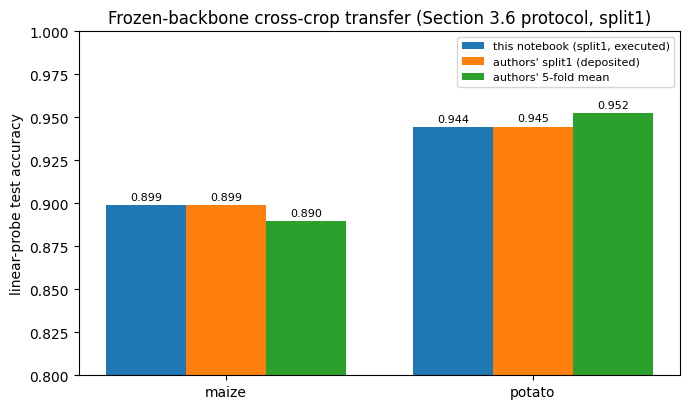

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
crops = ["maize", "potato"]
ours = [maize_res["acc"], potato_res["acc"]]
ref1 = [ref_split1[c]["acc"] for c in crops]
refm = [REF_MEAN[c]["acc"] for c in crops]
x = np.arange(len(crops)); w = 0.26
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(x - w, ours, w, label="this notebook (split1, executed)")
ax.bar(x,     ref1, w, label="authors' split1 (deposited)")
ax.bar(x + w, refm, w, label="authors' 5-fold mean")
ax.set_xticks(x); ax.set_xticklabels(crops)
ax.set_ylabel("linear-probe test accuracy")
ax.set_ylim(0.80, 1.0)
ax.set_title("Frozen-backbone cross-crop transfer (Section 3.6 protocol, split1)")
for i, (o, r1, rm) in enumerate(zip(ours, ref1, refm)):
    ax.text(i - w, o + 0.003, "%.3f" % o, ha="center", fontsize=8)
    ax.text(i,     r1 + 0.003, "%.3f" % r1, ha="center", fontsize=8)
    ax.text(i + w, rm + 0.003, "%.3f" % rm, ha="center", fontsize=8)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("/content/probe_comparison.png", dpi=110)
plt.show()

## 18. Qualitative check — predictions on held-out test images

EN: show held-out test images with the **true** class (from the authors' split list) and this notebook's **prediction** from the fitted head; misclassified images are marked. This visualizes the executed model on real inputs; it is not an author figure. JA: テスト画像に対する正解（著者分割リスト）と予測（本ノートブックのヘッド）を並べて表示します。誤分類は「MISCLASSIFIED」と明示します。

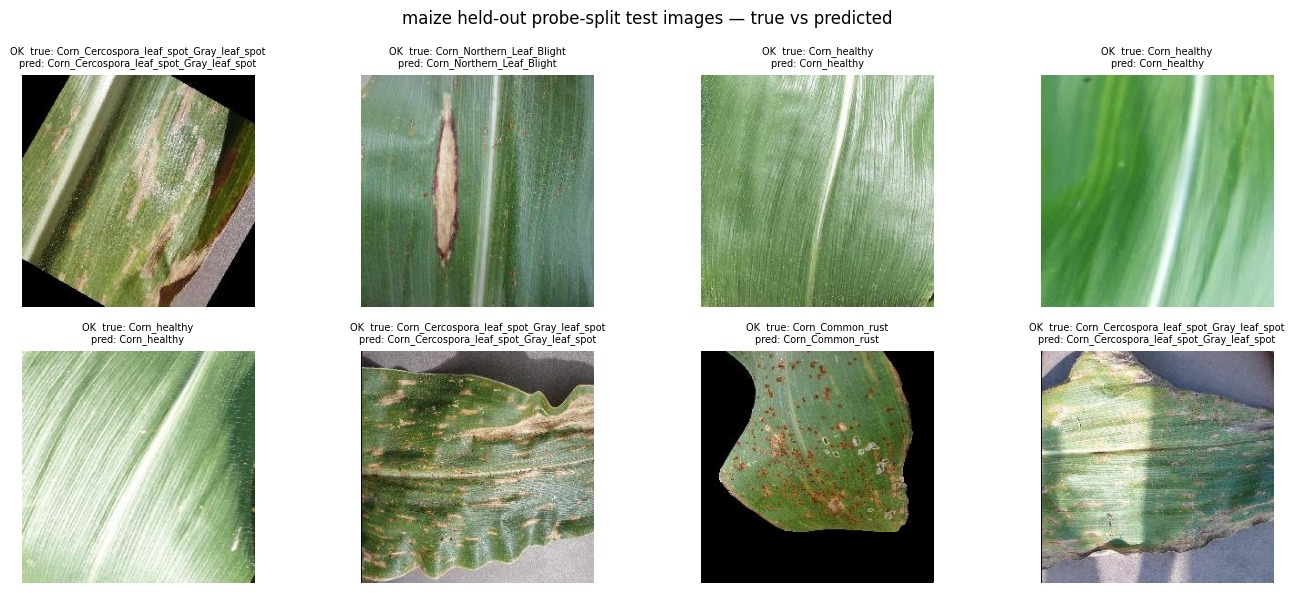

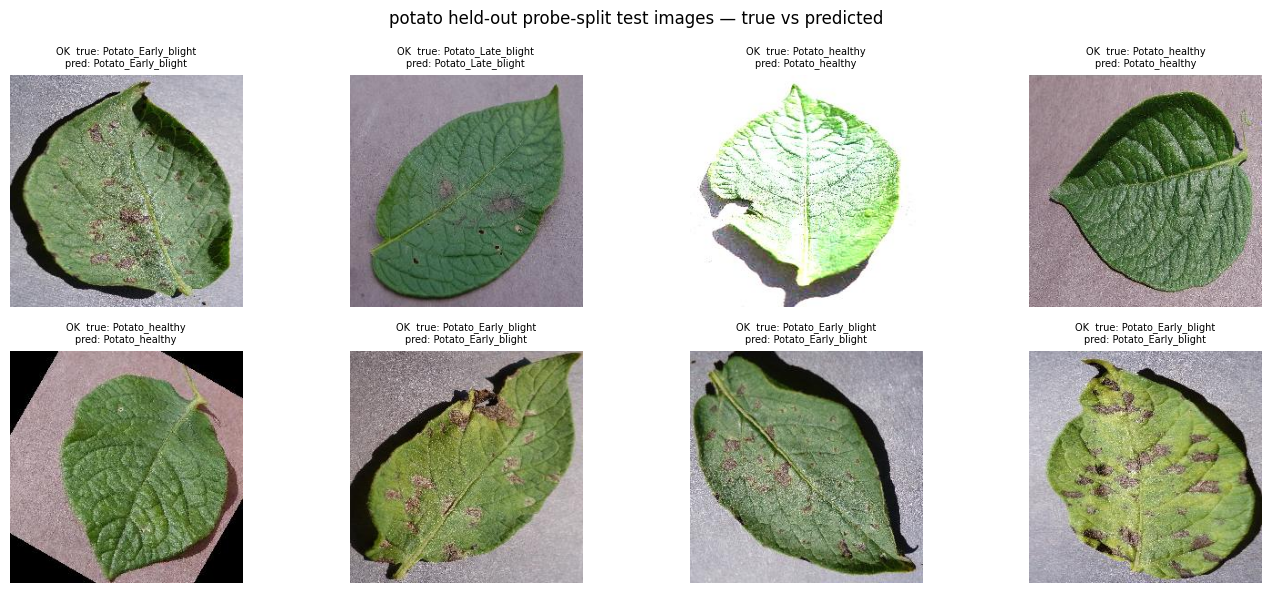

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

def predict_grid(model, crop, n=8, seed=1):
    classes = SPLITS[crop]["classes"]
    rng = random.Random(seed)
    picks = rng.sample(RESOLVED[crop]["test"], n)
    tf = pe.eval_tf()
    fig, axes = plt.subplots(2, 4, figsize=(14, 6))
    axes = axes.ravel()
    for ax, (path, ci) in zip(axes, picks):
        img = Image.open(path).convert("RGB")
        x = tf(img).unsqueeze(0).to(device)
        with torch.no_grad():
            pred = int(torch.argmax(model(x), dim=1))
        ok = pred == ci
        ax.imshow(img)
        ax.set_title(("OK  " if ok else "MISCLASSIFIED\n") +
                     "true: %s\npred: %s" % (classes[ci], classes[pred]),
                     fontsize=7, color="black" if ok else "red")
        ax.axis("off")
    fig.suptitle("%s held-out probe-split test images — true vs predicted" % crop)
    plt.tight_layout()
    plt.savefig("/content/predictions_%s.png" % crop, dpi=90)
    plt.show()

predict_grid(maize_model, "maize")
predict_grid(potato_model, "potato")

## 19. Interpretation, limitations, validation record

**What was executed.** The authors' released split1 fold weight (`best_split1.pt`, 58,439,571 bytes) was loaded into their exact `ModelC` architecture; their `fit_head` protocol (Section 3.6: frozen backbone, new linear head, Adam lr=1e-3, batch 8, 5 epochs, best-epoch head selected on the grouped test set) was run unmodified on the authors' leak-free grouped maize and potato probe splits. The comparison table above shows our executed split1 accuracy/F1 next to the authors' deposited split1 entry and their five-fold means (maize 88.99% ± 0.65 pp, potato 95.23% ± 1.34 pp).

**How to read the comparison.** Agreement within a small tolerance with the authors' deposited split1 entry supports that the released weight, split lists and protocol were used correctly. Differences of a few tenths of a percentage point can arise from hardware/library-version nondeterminism in a 5-epoch head fit; the authors' five-fold spread (±0.65 / ±1.34 pp) is the relevant natural variation scale. A single-fold probe is **not** a verification of the published dataset-level means, and the ImageNet-only control (89.13% / 88.61%) is cited, not re-run.

**Data provenance.** Maize images come from the vipoooool release cited in the authors' `provenance.json`; potato images come from the PlantifyDr collection because the potato probe-split names exist only there (all 9,485 entries resolved; see Section 6 for the documented discrepancy with `provenance.json`). Both archives were downloaded in full (~5.3 GB) because no smaller public subsets exist. The two duplicate trees inside the vipoooool archive were byte-identical on sampled MD5 pairs.

**Out of scope.** In-domain training of the five folds, the ablation matrix, the duplicate/leak audit, the perturbation robustness probe (its parameters are defined in the authors' `src/03_post_eval.py::Perturb`), the ImageNet-only control refit, and five-fold probe averaging.

**References.** Paper: Frontiers in Plant Science 17:1970636 (2026), DOI 10.3389/fpls.2026.1970636, PMC13755335. Code/partitions/results: github.com/czpbest/ccldr @ commit 616c65edb8311dedb64ffaf45794d013adb8fe53 (MIT / CC BY 4.0). Weights: release v1.0. Data: Kaggle vipoooool/new-plant-diseases-dataset and lavaman151/plantifydr-dataset (both derive from PlantVillage). PhenoPaper investigation run p-4213fbc6f337be535f4d500ec20c27a4-20261125T043511Z-1282027 was used as prior research guidance only.

JA: 著者のsplit1重みとプロトコルをそのまま実行し、著者配布のリーク無し分割で maize/potato の転移精度を再現しました。著者のsplit1値と概ね一致すれば、重み・分割・プロトコルの利用が正しいことを示します。potato画像はファイル名が一致するPlantifyDrコレクションから取得しました（provenance.jsonとの食い違いはSection 6に記載）。5-fold平均の検証やImageNetコントロールの再実行、摂動実験は範囲外です。